Download loan.csv (raw data) from https://www.kaggle.com/datasets/tanishaj225/loancsv and place it in the same folder as this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

=====
    LOADING ======


In [2]:
# Loading The Loan Dataset
loan = pd.read_csv("loan.csv", sep=",", low_memory=False)


# Understanding Dataset Dimensions & Target Variable Distribution
print(loan.shape)
print(loan["loan_status"].value_counts())


# Identifying Columns With Missing Values
missing = loan.isnull().sum().sort_values(ascending=False)
missing.head(60)

(39717, 111)
loan_status
Fully Paid     32950
Charged Off     5627
Current         1140
Name: count, dtype: int64


num_il_tl                         39717
num_bc_sats                       39717
num_bc_tl                         39717
num_actv_bc_tl                    39717
num_accts_ever_120_pd             39717
mths_since_recent_revol_delinq    39717
num_actv_rev_tl                   39717
mths_since_recent_inq             39717
num_tl_90g_dpd_24m                39717
num_tl_30dpd                      39717
num_tl_120dpd_2m                  39717
num_sats                          39717
num_rev_tl_bal_gt_0               39717
num_rev_accts                     39717
pct_tl_nvr_dlq                    39717
mo_sin_old_il_acct                39717
mo_sin_old_rev_tl_op              39717
mo_sin_rcnt_rev_tl_op             39717
mo_sin_rcnt_tl                    39717
mths_since_recent_bc              39717
mort_acc                          39717
mths_since_recent_bc_dlq          39717
bc_util                           39717
total_rev_hi_lim                  39717
all_util                          39717


=====
    CLEANING & TRANSFORMATION ======


In [3]:
# Removing Columns Containing Only Missing Values (100% Null)
loan = loan.dropna(axis=1, how="all")


# Filtering Dataset To Include Only Completed Loans
# Excludes ongoing loans to avoid mixing incomplete outcomes with completed ones
loan = loan[loan["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()


# 1 = Charged Off (Default), 0 = Fully Paid (Non-Default)
loan["is_default"] = (loan["loan_status"] == "Charged Off").astype(int)


# Reviewing Dataset
loan.info()

<class 'pandas.DataFrame'>
Index: 38577 entries, 0 to 39716
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          38577 non-null  int64  
 1   member_id                   38577 non-null  int64  
 2   loan_amnt                   38577 non-null  int64  
 3   funded_amnt                 38577 non-null  int64  
 4   funded_amnt_inv             38577 non-null  float64
 5   term                        38577 non-null  str    
 6   int_rate                    38577 non-null  str    
 7   installment                 38577 non-null  float64
 8   grade                       38577 non-null  str    
 9   sub_grade                   38577 non-null  str    
 10  emp_title                   36191 non-null  str    
 11  emp_length                  37544 non-null  str    
 12  home_ownership              38577 non-null  str    
 13  annual_inc                  38577 non-null  flo

In [4]:
# Calculating Principal Loss On Defaulted Loans
# Principal loss = Funded amount - Principal repaid
# Non-defaulted loans are assigned zero principal loss.

loan["principal_lost"] = 0.0
mask = loan["is_default"] == 1

loan.loc[mask, "principal_lost"] = (
    loan.loc[mask, "funded_amnt"] - loan.loc[mask, "total_rec_prncp"]
)


# Calculating Net Financial Result For Each Loan
# Net result = Total payments received - Funded amount
# Positive = Amount received exceeded funded amount
# Negative = Amount received was less than funded amount

loan["net_result"] = loan["total_pymnt"] - loan["funded_amnt"]


# Checking Updated Dataset Dimensions
loan.shape

(38577, 60)

In [5]:
# Converting Text-Based Numerical Columns Into Numeric Data Types

# Extracting numeric values from loan term (e.g. "36 months" -> 36)
loan["term"] = loan["term"].str.extract(r"(\d+)")[0].astype(int)

# Removing percentage symbols and converting to numeric values
loan["int_rate"] = loan["int_rate"].str.replace("%", "").astype(float)
loan["revol_util"] = loan["revol_util"].str.replace("%", "").astype(float)

# Converting employment length into numeric years (e.g. "< 1 year" -> 0, "10+ years" -> 10)
loan["emp_length"] = loan["emp_length"].str.replace("< 1 year", "0 years")
loan["emp_length"] = loan["emp_length"].str.extract(r"(\d+)")[0].astype(float)


# Converting Date Columns & Correcting Two-Digit Year Interpretation

loan["issue_d"] = pd.to_datetime(loan["issue_d"], format="%b-%y", errors="coerce")
loan["earliest_cr_line"] = pd.to_datetime(loan["earliest_cr_line"], format="%b-%y")

# Correcting credit history dates incorrectly interpreted as future years
bad = loan["earliest_cr_line"] > loan["issue_d"]
loan.loc[bad, "earliest_cr_line"] -= pd.DateOffset(years=100)


# Creating Derived Features For Further Analysis

# Extracting loan issue year
loan["issue_year"] = loan["issue_d"].dt.year

# Calculating borrower's credit history length in years
loan["credit_history_year"] = (
    loan["issue_d"] - loan["earliest_cr_line"]
).dt.days / 365.25

# Creating binary indicators for previous delinquencies and public records
loan["has_prior_delinq"] = loan["mths_since_last_delinq"].notna().astype(int)
loan["has_public_record"] = loan["mths_since_last_record"].notna().astype(int)

In [6]:
# Dropping Unnecessary, Redundant & Data-Leakage Columns

# Identifiers and text columns not required for the current analysis
ids_text = ["id", "member_id", "url", "desc", "title", "emp_title", "zip_code"]

# Columns carrying information already represented by other variables
redundant = ["funded_amnt", "funded_amnt_inv", "earliest_cr_line"]

# Removing post-loan outcome information to prevent data leakage
leakage = ["out_prncp", "out_prncp_inv", "total_pymnt", "total_pymnt_inv",
           "total_rec_prncp", "total_rec_int", "total_rec_late_fee", "recoveries",
           "collection_recovery_fee", "last_pymnt_d", "last_pymnt_amnt",
           "last_credit_pull_d"]

loan = loan.drop(columns=ids_text + redundant + leakage)


# Dropping Columns With No Variability (Single Unique Value)

# Identifying columns containing only one unique value, including missing values
single = [c for c in loan.columns if loan[c].nunique(dropna=True) <= 1]
print("Single-value columns dropped:", single)

loan = loan.drop(columns=single)

Single-value columns dropped: ['pymnt_plan', 'initial_list_status', 'next_pymnt_d', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'chargeoff_within_12_mths', 'delinq_amnt', 'tax_liens']


In [7]:
# Creating Bands For Key Metrics
# Grouping continuous numerical variables into meaningful ranges
# to analyse default rates across different customer segments

loan["income_band"] = pd.cut(loan["annual_inc"], 
    bins= [0, 30000, 50000, 75000, 100000, float("inf")],
    labels= ["<30k","30k-50k","50-75k","75-100k","100k+"], right=False)

loan["dti_band"] = pd.cut(loan["dti"],
    bins= [0, 10, 15, 20, 25, float("inf")],
    labels= ["<10", "10-15","15-20", "20-25", "25+"], right=False)

loan["loan_amnt_band"] = pd.cut(loan["loan_amnt"],
    bins= [0, 5000, 10000, 20000, 30000, float("inf")],
    labels= ["<5k","5k-10k","10k-20k","20k-30k","30k+"], right=False)

loan["int_rate_band"] = pd.cut(loan["int_rate"],
    bins=[0, 8, 11, 14, 17, float("inf")],
    labels=["<8%", "8-11%", "11-14%", "14-17%", "17%+"], right=False)



=====
    ANALYSIS ======


In [8]:
# Spread Of Key Numeric Cols (Check Outliers)
print(loan[["annual_inc", "dti", "loan_amnt", "int_rate", "revol_util", "credit_history_year"]]
      .describe(percentiles=(.01, .5, .99)).round(2))


       annual_inc       dti  loan_amnt  int_rate  revol_util  \
count    38577.00  38577.00   38577.00  38577.00    38527.00   
mean     68777.97     13.27   11047.03     11.93       48.70   
std      64218.68      6.67    7348.44      3.69       28.36   
min       4000.00      0.00     500.00      5.42        0.00   
1%       14400.00      0.35    1200.00      5.42        0.00   
50%      58868.00     13.37    9600.00     11.71       49.10   
99%     234144.00     26.53   35000.00     20.99       98.50   
max    6000000.00     29.99   35000.00     24.40       99.90   

       credit_history_year  
count             38577.00  
mean                 13.72  
std                   6.83  
min                   3.00  
1%                    3.42  
50%                  12.50  
99%                  35.94  
max                  65.41  


In [9]:
# Analysing Default Rates & Loan Counts Across Different Segments

for col in ["grade", "term", "income_band", "dti_band", "loan_amnt_band", "int_rate_band"]:
    print(loan.groupby(col, observed=True)["is_default"]
              .agg(count="count", default_rate="mean")
              .round(3)
              .sort_values("default_rate", ascending=False), "\n")


# Analysing Loan Amount Impact On Default Rates Across Credit Grades

loan_size = loan.groupby(["grade", "loan_amnt_band"])["is_default"].mean().mul(100).round(2).unstack()
print(loan_size)

       count  default_rate
grade                     
G        299         0.338
F        976         0.327
E       2663         0.268
D       5085         0.220
C       7834         0.172
B      11675         0.122
A      10045         0.060 

      count  default_rate
term                     
60     9481         0.253
36    29096         0.111 

             count  default_rate
income_band                     
<30k          3743         0.187
30k-50k      10617         0.165
50-75k       11911         0.146
75-100k       6327         0.125
100k+         5979         0.108 

          count  default_rate
dti_band                     
20-25      6599         0.170
15-20      8824         0.158
10-15      9624         0.145
25+         625         0.139
<10       12905         0.126 

                count  default_rate
loan_amnt_band                     
30k+             1072         0.232
20k-30k          4735         0.178
10k-20k         13305         0.146
<5k              7444   

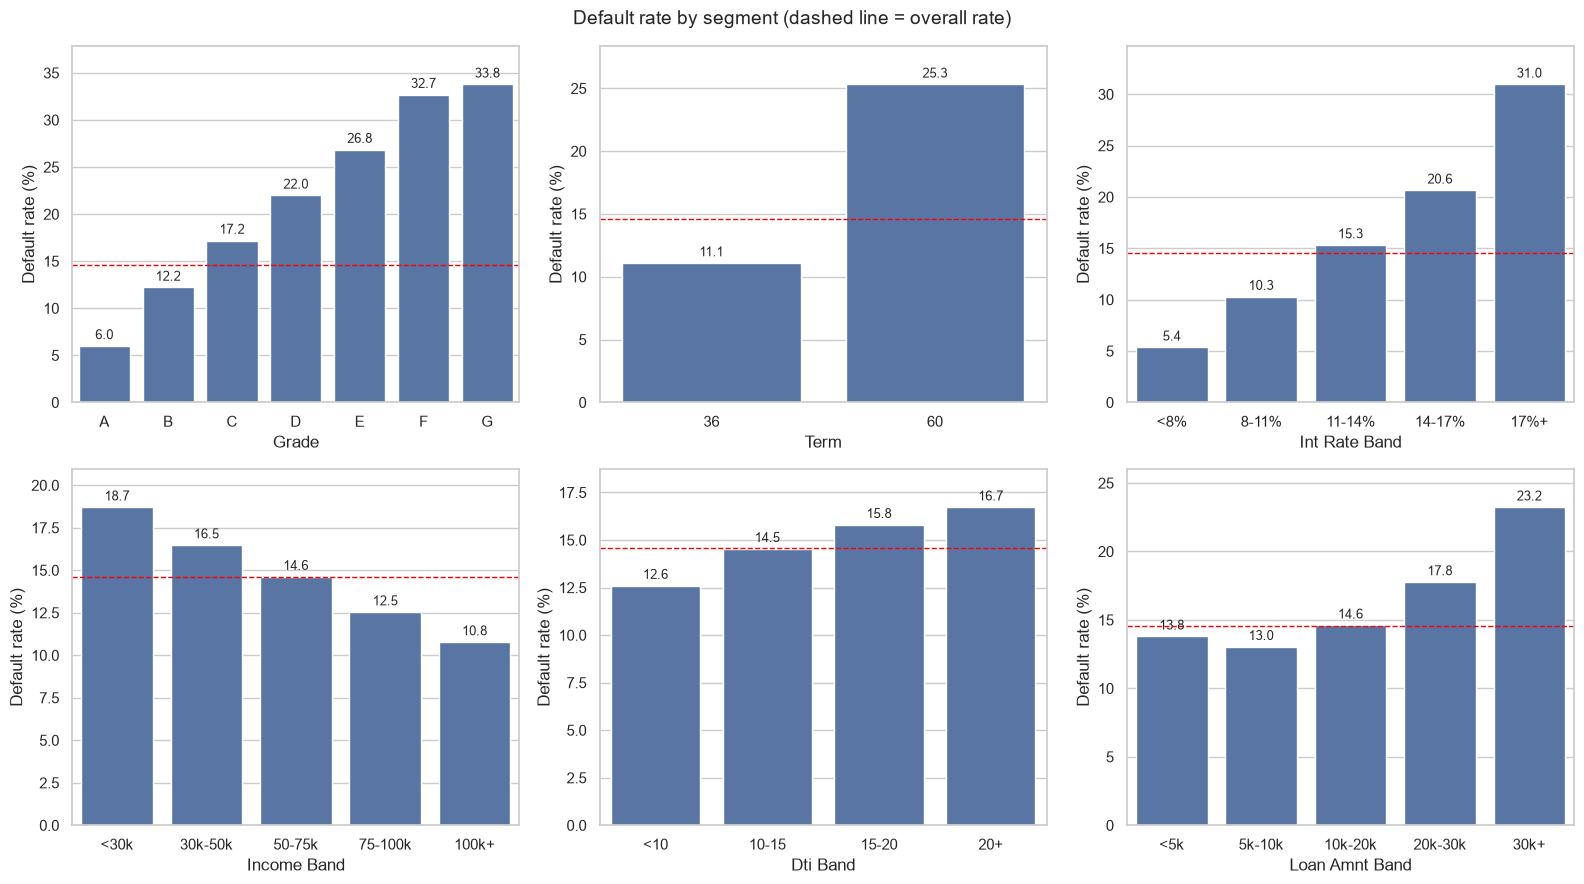

In [10]:
# Combining Higher DTI Categories To Create More Balanced Groups
loan["dti_band"] = pd.cut(loan["dti"],
    bins=[0, 10, 15, 20, float("inf")],
    labels=["<10", "10-15", "15-20", "20+"], right=False)


# Setting Visualization Style & Calculating Overall Default Rate
sns.set_theme(style="whitegrid")

loan["default_pct"] = loan["is_default"] * 100
overall = loan["default_pct"].mean()  # Overall Default Rate (%)


# Creating Reusable Function To Plot Default Rates By Segment
def rate_chart(col, ax, order=None):
    sns.barplot(data=loan, x=col, y="default_pct", order=order,
                errorbar=None, ax=ax)

    ax.axhline(overall, color="red", linestyle="--", linewidth=1)
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Default rate (%)")
    ax.bar_label(ax.containers[0], fmt="%.1f", padding=3, fontsize=9)
    ax.margins(y=0.12)


# Generating Comparative Default Rate Charts Across Six Key Segments
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

rate_chart("grade", axes[0, 0], order=sorted(loan["grade"].unique()))
rate_chart("term", axes[0, 1], order=[36, 60])
rate_chart("int_rate_band", axes[0, 2])
rate_chart("income_band", axes[1, 0])
rate_chart("dti_band", axes[1, 1])
rate_chart("loan_amnt_band", axes[1, 2])

fig.suptitle("Default rate by segment (dashed line = overall rate)", fontsize=14)
plt.tight_layout()
plt.show()

              count         default_rate       
term             36      60           36     60
issue_year                                     
2007          251.0     NaN        0.179    NaN
2008         1562.0     NaN        0.158    NaN
2009         4716.0     NaN        0.126    NaN
2010         8466.0  3066.0        0.099  0.210
2011        14101.0  6415.0        0.106  0.274


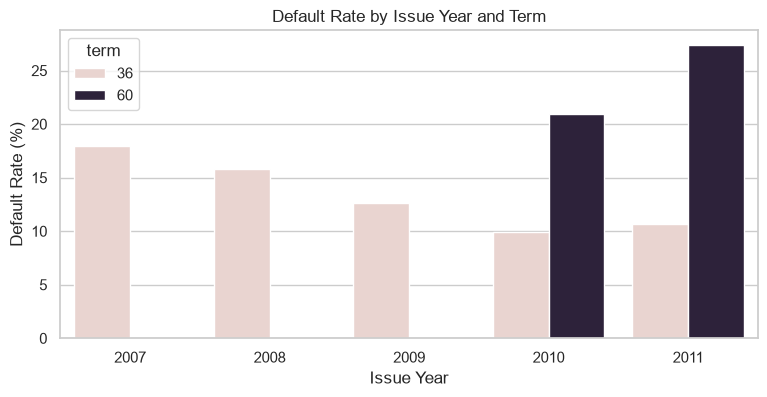

In [11]:
# Analysing Default Rates & Loan Counts By Issue Year And Loan Term
table = loan.groupby(["issue_year", "term"])["is_default"].agg(
    count="count", default_rate="mean"
).round(3)

print(table.unstack())


# Visualising Default Rate Trends Across Issue Years And Loan Terms
plt.figure(figsize=(9, 4))

ax = sns.barplot(data=loan, x="issue_year", y="default_pct",
                 hue="term", errorbar=None)

plt.ylabel("Default Rate (%)")
plt.xlabel("Issue Year")
plt.title("Default Rate by Issue Year and Term")
plt.show()

In [12]:
# Analysing Loan Performance & Financial Losses Across Credit Grades

by_grade = loan.groupby("grade").agg(
    loans=("is_default", "count"),
    default_rate=("is_default", "mean"),
    total_lent=("loan_amnt", "sum"),
    principal_lost=("principal_lost", "sum"),
    net_result=("net_result", "sum"),
)

# Calculating Default Rate, Loan Share, Loss Contribution & Loss Rate
by_grade["default_rate"] = by_grade["default_rate"] * 100
by_grade["share_of_loans_%"] = by_grade["loans"] / by_grade["loans"].sum() * 100
by_grade["share_of_losses_%"] = by_grade["principal_lost"] / by_grade["principal_lost"].sum() * 100
by_grade["loss_rate_%"] = by_grade["principal_lost"] / by_grade["total_lent"] * 100

print(by_grade.round(1))

# Analysing Loan Performance & Financial Losses Across Loan Terms

by_term = loan.groupby("term").agg(
    loans=("is_default", "count"),
    default_rate=("is_default", "mean"),
    total_lent=("loan_amnt", "sum"),
    principal_lost=("principal_lost", "sum"),
    net_result=("net_result", "sum"),
)

# Calculating Default Rate, Loan Share, Loss Contribution & Loss Rate
by_term["default_rate"] = by_term["default_rate"] * 100
by_term["share_of_loans_%"] = by_term["loans"] / by_term["loans"].sum() * 100
by_term["share_of_losses_%"] = by_term["principal_lost"] / by_term["principal_lost"].sum() * 100
by_term["loss_rate_%"] = by_term["principal_lost"] / by_term["total_lent"] * 100

print(by_term.round(1))

       loans  default_rate  total_lent  principal_lost  net_result  \
grade                                                                
A      10045           6.0    86575425       2555350.0   6065125.5   
B      11675          12.2   127663600       9243984.8  11962568.2   
C       7834          17.2    84728775       9546985.0   8774930.2   
D       5085          22.0    61720550       8996581.3   6788437.2   
E       2663          26.8    41756150       7707659.0   5248474.6   
F        976          32.7    17660950       4301168.1   2109489.1   
G        299          33.8     6055650       1461336.5    826465.9   

       share_of_loans_%  share_of_losses_%  loss_rate_%  
grade                                                    
A                  26.0                5.8          3.0  
B                  30.3               21.1          7.2  
C                  20.3               21.8         11.3  
D                  13.2               20.5         14.6  
E                   6

=====
    STATISTICS ======


mean: 68778
median: 58868
std: 64219
skew: 31.2
outlier limit: 145000
loans above the limit: 1762


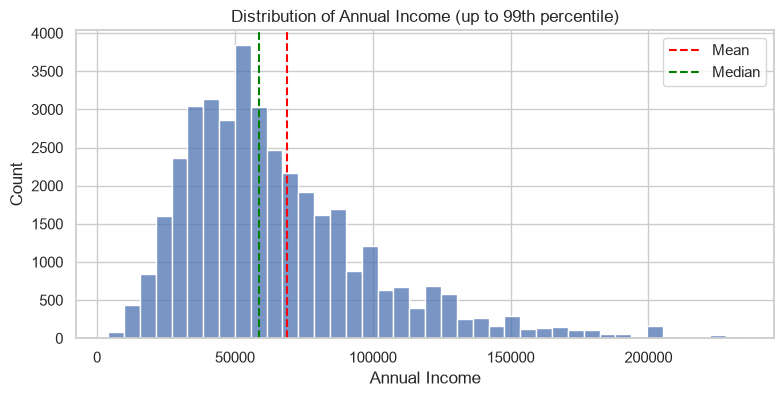

In [13]:
# Analysing Annual Income Distribution Using Descriptive Statistics

col = loan["annual_inc"]

print("mean:", round(col.mean()))
print("median:", round(col.median()))
print("std:", round(col.std()))
print("skew:", round(col.skew(), 2))


# Detecting Potential Outliers Using the IQR Method

q1, q3 = col.quantile([0.25, 0.75])
iqr = q3 - q1

upper_limit = q3 + 1.5 * iqr

print("outlier limit:", round(upper_limit))
print("loans above the limit:", (col > upper_limit).sum())


# Visualising Annual Income Distribution (Excluding Top 1% For Display)

cap = col.quantile(0.99)

plt.figure(figsize=(9, 4))
sns.histplot(col[col <= cap], bins=40)

plt.axvline(col.mean(), color="red", linestyle="--", label="Mean")
plt.axvline(col.median(), color="green", linestyle="--", label="Median")

plt.legend()
plt.xlabel("Annual Income")
plt.title("Distribution of Annual Income (up to 99th percentile)")
plt.show()

       defaults  loans  rate_%  ci_low_%  ci_high_%
grade                                              
A           602  10045     6.0       5.5        6.5
B          1425  11675    12.2      11.6       12.8
C          1347   7834    17.2      16.4       18.0
D          1118   5085    22.0      20.8       23.1
E           715   2663    26.8      25.2       28.5
F           319    976    32.7      29.7       35.6
G           101    299    33.8      28.4       39.1


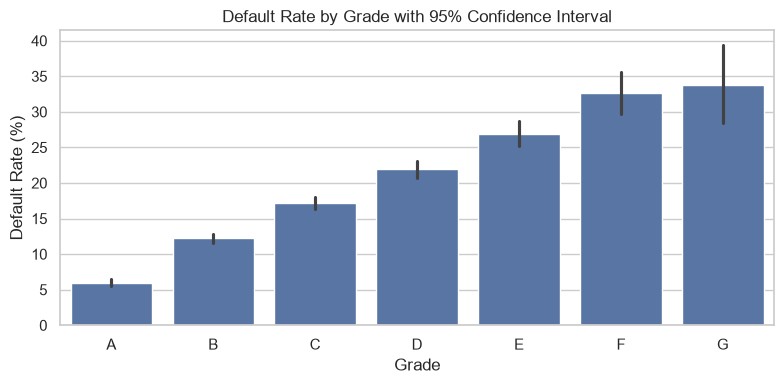

In [14]:
# Calculating Default Rates & 95% Confidence Intervals Across Credit Grades

from statsmodels.stats.proportion import proportion_confint

# Calculating Default Counts & Total Loans For Each Grade
g = loan.groupby("grade")["is_default"].agg(
    defaults="sum",
    loans="count"
)

# Calculating Default Rate (%)
g["rate_%"] = g["defaults"] / g["loans"] * 100

# Calculating 95% Confidence Intervals Using Normal Approximation
low, high = proportion_confint(
    g["defaults"], g["loans"], alpha=0.05, method="normal"
)

g["ci_low_%"] = low * 100
g["ci_high_%"] = high * 100

print(g.round(1))


# Visualising Default Rates With 95% Confidence Intervals Across Grades

plt.figure(figsize=(8, 4))

ax = sns.barplot(
    data=loan,
    x="grade",
    y="default_pct",
    errorbar=("ci", 95),
    order=sorted(loan["grade"].unique())
)

plt.ylabel("Default Rate (%)")
plt.xlabel("Grade")
plt.title("Default Rate by Grade with 95% Confidence Interval")
plt.tight_layout()
plt.show()

In [15]:
# Testing Association Between Categorical Variables & Loan Defaults
# Chi-Square Test identifies statistical significance, while Cramér's V measures association strength.

from scipy.stats import chi2_contingency

results = []

# Performing Chi-Square Test & Calculating Cramér's V For Each Variable
for col in ["grade", "term", "purpose", "home_ownership", "verification_status",
            "income_band", "dti_band", "int_rate_band", "loan_amnt_band", "emp_length"]:

    table = pd.crosstab(loan[col], loan["is_default"])

    chi2, p, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    k = min(table.shape) - 1

    v = (chi2 / (n * k)) ** 0.5

    results.append({
        "column": col,
        "chi2": round(chi2, 1),
        "p_value": p,
        "cramers_v": round(v, 3),
        "min_expected": round(expected.min(), 1)
    })


# Ranking Variables By Strength Of Association With Default
results_df = pd.DataFrame(results).sort_values("cramers_v", ascending=False)

# Standardising Home Ownership Categories
loan["home_ownership"] = loan["home_ownership"].str.replace({"NONE": "OTHER"})

print(results_df)

                column    chi2        p_value  cramers_v  min_expected
7        int_rate_band  1651.1   0.000000e+00      0.207         518.7
0                grade  1581.2   0.000000e+00      0.202          43.6
1                 term  1159.9  3.109544e-254      0.173        1382.9
2              purpose   378.9   6.213959e-73      0.099          14.9
5          income_band   172.5   3.046945e-36      0.067         546.0
8       loan_amnt_band   129.5   4.982096e-27      0.058         156.4
4  verification_status    89.9   3.076699e-20      0.048        1411.5
6             dti_band    77.7   9.371154e-17      0.045        1053.7
3       home_ownership    22.2   1.801171e-04      0.024           0.4
9           emp_length    22.1   1.454934e-02      0.024         176.3


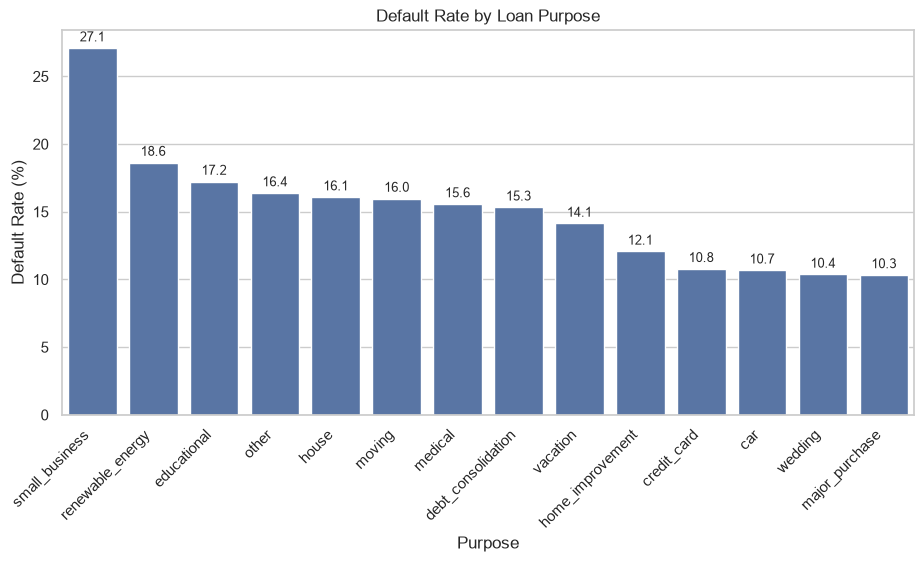

                    defaults  loans  rate_%  ci_low_%  ci_high_%
purpose                                                         
small_business           475   1754    27.1      25.1       29.2
renewable_energy          19    102    18.6      12.3       27.3
educational               56    325    17.2      13.5       21.7
other                    633   3865    16.4      15.2       17.6
house                     59    367    16.1      12.7       20.2
moving                    92    576    16.0      13.2       19.2
medical                  106    681    15.6      13.0       18.5
debt_consolidation      2767  18055    15.3      14.8       15.9
vacation                  53    375    14.1      11.0       18.0
home_improvement         347   2875    12.1      10.9       13.3
credit_card              542   5027    10.8      10.0       11.7
car                      160   1499    10.7       9.2       12.3
wedding                   96    926    10.4       8.6       12.5
major_purchase           

In [16]:
# Analysing Default Rates Across Different Loan Purposes

# Ordering loan purposes from highest to lowest default rate
order = loan.groupby("purpose")["is_default"].mean().sort_values(ascending=False).index

# Visualising Default Rates By Loan Purpose
plt.figure(figsize=(11, 5))
ax = sns.barplot(data=loan, x="purpose", y="default_pct",
                 order=order, errorbar=None)

ax.bar_label(ax.containers[0], fmt="%.1f", padding=3, fontsize=9)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Default Rate (%)")
plt.xlabel("Purpose")
plt.title("Default Rate by Loan Purpose")
plt.show()


# Calculating Default Rates & 95% Wilson Confidence Intervals By Loan Purpose

p = loan.groupby("purpose")["is_default"].agg(
    defaults="sum",
    loans="count"
)

p["rate_%"] = p["defaults"] / p["loans"] * 100

# Using Wilson Method To Estimate Confidence Intervals
low, high = proportion_confint(
    p["defaults"], p["loans"], alpha=0.05, method="wilson"
)

p["ci_low_%"] = low * 100
p["ci_high_%"] = high * 100

print(p.sort_values("rate_%", ascending=False).round(1))

In [17]:
# Comparing Numerical Variables Between Paid & Defaulted Loans
# Using Mann–Whitney U Test

from scipy.stats import mannwhitneyu

# Separating Paid & Defaulted Loan Groups
paid = loan[loan["is_default"] == 0]
defaulted = loan[loan["is_default"] == 1]

# Testing Differences In Numerical Variables Between The Two Groups
rows = []

for col in ["annual_inc", "dti", "int_rate", "revol_util",
            "loan_amnt", "credit_history_year"]:

    a = paid[col].dropna()
    b = defaulted[col].dropna()

    u, p = mannwhitneyu(a, b, alternative="two-sided")

    rows.append({
        "column": col,
        "median_paid": a.median(),
        "median_default": b.median(),
        "p_value": p,
        "prob_paid_higher": u / (len(a) * len(b))
    })

# Displaying Group Medians & Statistical Test Results
print(pd.DataFrame(rows).round(3))

                column  median_paid  median_default  p_value  prob_paid_higher
0           annual_inc    60000.000       53000.000    0.000             0.557
1                  dti       13.200          14.290    0.000             0.462
2             int_rate       11.490          13.610    0.000             0.334
3           revol_util       47.600          58.400    0.000             0.418
4            loan_amnt     9600.000       10000.000    0.000             0.461
5  credit_history_year       12.504          12.252    0.003             0.512


In [18]:
# Relative Risk Analysis
# Compares default rates against a selected reference category.

def rr_table(col, reference):

    # Calculate default rate (%) for each category.
    rates = loan.groupby(col, observed=True)["is_default"].mean() * 100

    # Calculate difference in percentage points from the reference.
    out = pd.DataFrame({"default_rate_%": rates})
    out["diff_pts"] = out["default_rate_%"] - rates[reference]

    # Calculate relative risk compared to the reference category.
    out["relative_risk"] = out["default_rate_%"] / rates[reference]

    return out.round(2)


print(rr_table("term", 36))
print(rr_table("grade", "A"))
print(rr_table("purpose", "debt_consolidation"))

      default_rate_%  diff_pts  relative_risk
term                                         
36             11.09      0.00           1.00
60             25.31     14.22           2.28
       default_rate_%  diff_pts  relative_risk
grade                                         
A                5.99      0.00           1.00
B               12.21      6.21           2.04
C               17.19     11.20           2.87
D               21.99     15.99           3.67
E               26.85     20.86           4.48
F               32.68     26.69           5.45
G               33.78     27.79           5.64
                    default_rate_%  diff_pts  relative_risk
purpose                                                    
car                          10.67     -4.65           0.70
credit_card                  10.78     -4.54           0.70
debt_consolidation           15.33      0.00           1.00
educational                  17.23      1.91           1.12
home_improvement             12.0

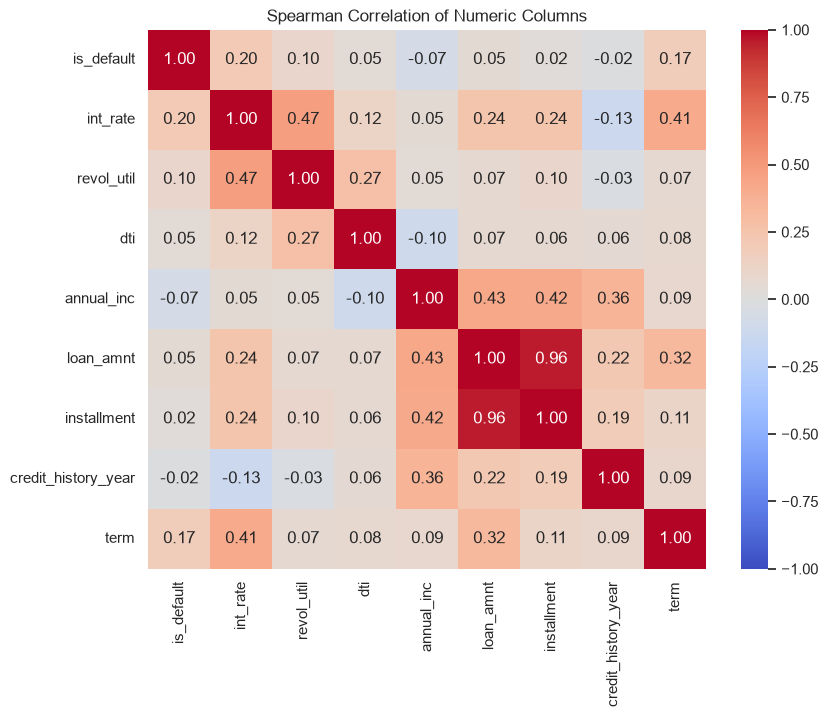

In [19]:
# Spearman Correlation Analysis

# Select numeric columns for correlation analysis.
num_cols = ["is_default", "int_rate", "revol_util", "dti", "annual_inc",
            "loan_amnt", "installment", "credit_history_year", "term"]

# Calculate Spearman correlation between selected columns.
corr = loan[num_cols].corr(method="spearman")

# Visualize correlations using a heatmap.
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman Correlation of Numeric Columns")
plt.show()

=====
    EXPORTING CLEAN DATA ======


In [20]:
# Export Cleaned Dataset

# Create a copy of the cleaned dataset for export.
export = loan.copy()

# Convert categorical bands into ordered numeric codes
# and categories into strings for CSV compatibility.
for band in ["income_band", "dti_band", "loan_amnt_band", "int_rate_band"]:
    if band in export.columns:
        export[band + "_order"] = export[band].cat.codes + 1
        export[band] = export[band].astype(str)

# Remove unnecessary column and export dataset to CSV.
export = export.drop(columns=["default_pct"])
export.to_csv("loan_clean.csv", index=False)

# Display final dataset dimensions.
print(export.shape)

(38577, 40)
